24BAD010-Anusri T


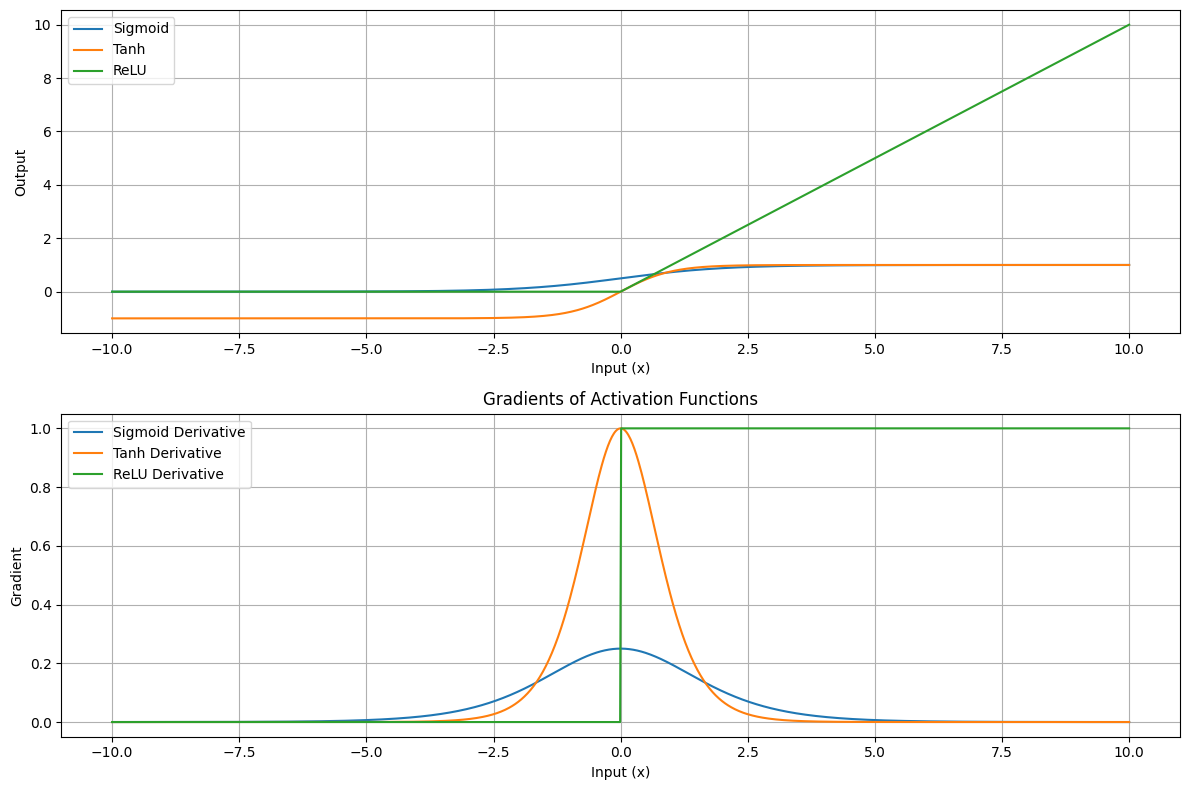

In [ ]:
print("24BAD010-Anusri T")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

x = np.linspace(-10, 10, 1000)
sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)

sigmoid_derivative = sigmoid * (1 - sigmoid)
tanh_derivative = 1 - tanh**2
relu_derivative = np.where(x > 0, 1, 0)
plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)
plt.plot(x, sigmoid, label="Sigmoid")
plt.plot(x, tanh, label="Tanh")
plt.plot(x, relu, label="ReLU")
plt.xlabel("Input (x)")
plt.ylabel("Output")
plt.grid(True)
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(x, sigmoid_derivative, label="Sigmoid Derivative")
plt.plot(x, tanh_derivative, label="Tanh Derivative")
plt.plot(x, relu_derivative, label="ReLU Derivative")
plt.title("Gradients of Activation Functions")
plt.xlabel("Input (x)")
plt.ylabel("Gradient")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

24BAD010-Anusri T
TensorFlow Version: 2.20.0
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)

Training with: sigmoid
Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8000 - loss: 0.8724 - val_accuracy: 0.9150 - val_loss: 0.3364
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9193 - loss: 0.2956 - val_accuracy: 0.9367 - val_loss: 0.2306
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9358 - loss: 0.2225 - val_accuracy: 0.9469 - val_loss: 0.1899
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9476 - loss: 0.1811 - val_accuracy: 0.9546 - val_loss: 0.1616
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9553 - loss: 0.1520 - val_accuracy: 0.9596 - val_loss: 0.1403
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9629 - loss: 0.1286 - val_accuracy: 0.9634 - val_loss: 0.1267
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9679 - loss: 0.1097 - va

,Activation,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Best Epoch
0,sigmoid,0.9978,0.9790,0.0141,0.0754,20
1,tanh,1.0000,0.9794,0.0011,0.0868,18
2,relu,0.9984,0.9773,0.0059,0.1124,12


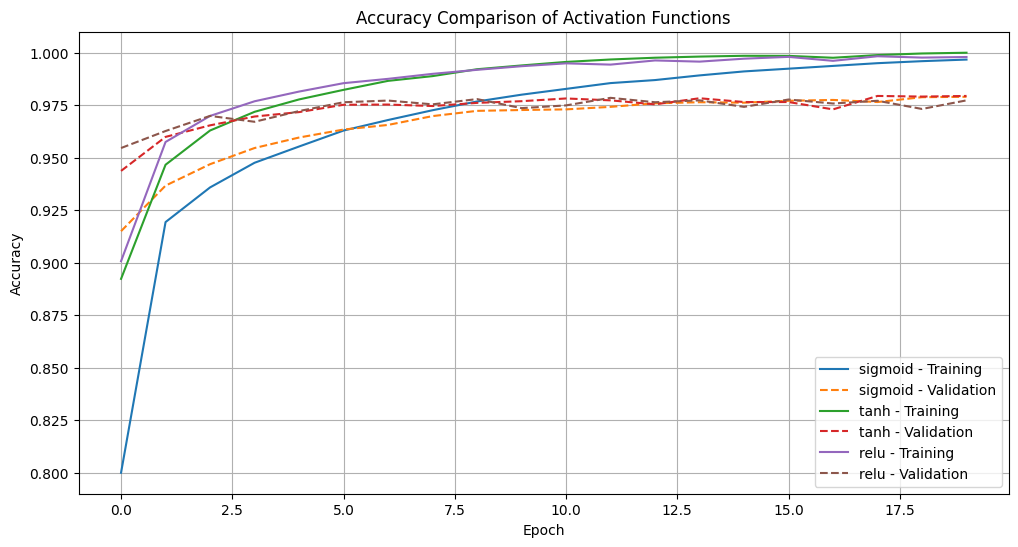

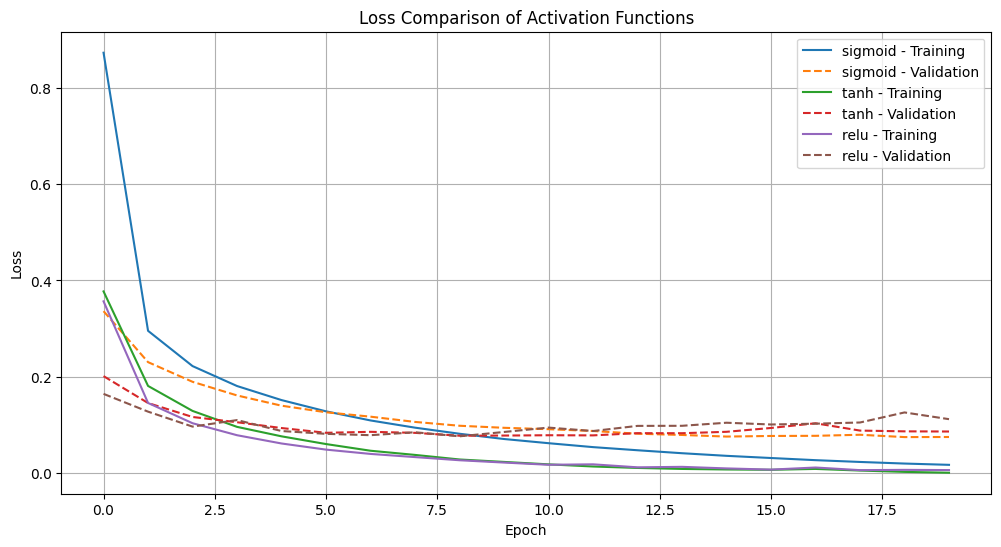

In [ ]:
print("24BAD010-Anusri T")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
print("TensorFlow Version:", tf.__version__)


(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training data shape:", x_train.shape)
print("Testing data shape:", x_test.shape)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

validation_size = 10000

x_val = x_train[-validation_size:]
y_val = y_train[-validation_size:]

x_train_new = x_train[:-validation_size]
y_train_new = y_train[:-validation_size]

def create_model(activation):

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(784,)),

        tf.keras.layers.Dense(128, activation=activation),
        tf.keras.layers.Dense(64, activation=activation),

        tf.keras.layers.Dense(10, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

activations = ["sigmoid", "tanh", "relu"]

histories = {}
models = {}

EPOCHS = 20
BATCH_SIZE = 128

for activation in activations:

    print("\n" + "=" * 60)
    print("Training with:", activation)
    print("=" * 60)

    model = create_model(activation)

    history = model.fit(
        x_train_new,
        y_train_new,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    histories[activation] = history
    models[activation] = model
results = []

for activation in activations:

    model = models[activation]

    train_loss, train_accuracy = model.evaluate(
        x_train_new,
        y_train_new,
        verbose=0
    )

    val_loss, val_accuracy = model.evaluate(
        x_val,
        y_val,
        verbose=0
    )

    history = histories[activation]
    best_epoch = np.argmax(history.history["val_accuracy"]) + 1

    results.append({
        "Activation": activation,
        "Training Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Training Loss": train_loss,
        "Validation Loss": val_loss,
        "Best Epoch": best_epoch
    })

results_df = pd.DataFrame(results)

print("\nFINAL COMPARISON")
print("=" * 80)

display(results_df.round(4))
plt.figure(figsize=(12, 6))

for activation in activations:

    history = histories[activation]

    plt.plot(
        history.history["accuracy"],
        label=activation + " - Training"
    )

    plt.plot(
        history.history["val_accuracy"],
        linestyle="--",
        label=activation + " - Validation"
    )

plt.title("Accuracy Comparison of Activation Functions")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()
plt.show()
plt.figure(figsize=(12, 6))

for activation in activations:

    history = histories[activation]

    plt.plot(
        history.history["loss"],
        label=activation + " - Training"
    )

    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=activation + " - Validation"
    )

plt.title("Loss Comparison of Activation Functions")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()

24BAD010-Anusri T

Optimizer: SGD
Epoch 1/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6505 - loss: 1.3828 - val_accuracy: 0.8493 - val_loss: 0.6843
Epoch 2/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8566 - loss: 0.5730 - val_accuracy: 0.8890 - val_loss: 0.4284
Epoch 3/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8842 - loss: 0.4262 - val_accuracy: 0.9032 - val_loss: 0.3546
Epoch 4/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8973 - loss: 0.3674 - val_accuracy: 0.9098 - val_loss: 0.3175
Epoch 5/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9060 - loss: 0.3331 - val_accuracy: 0.9168 - val_loss: 0.2930
Epoch 6/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9124 - loss: 0.3095 - val_accuracy: 0.9205 - val_loss: 0.2776
Epoch 7/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9169 - loss: 0.2914 - val_accuracy: 0.9229 - val_loss: 0.2629
Epoch 8/20
391/391 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9212

,Optimizer,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Best Epoch
0,SGD,0.9477,0.9516,0.1820,0.1790,20
1,Momentum,0.9969,0.9768,0.0174,0.0823,17
2,RMSProp,0.9989,0.9785,0.0040,0.1142,19
3,Adam,0.9996,0.9776,0.0024,0.1037,15


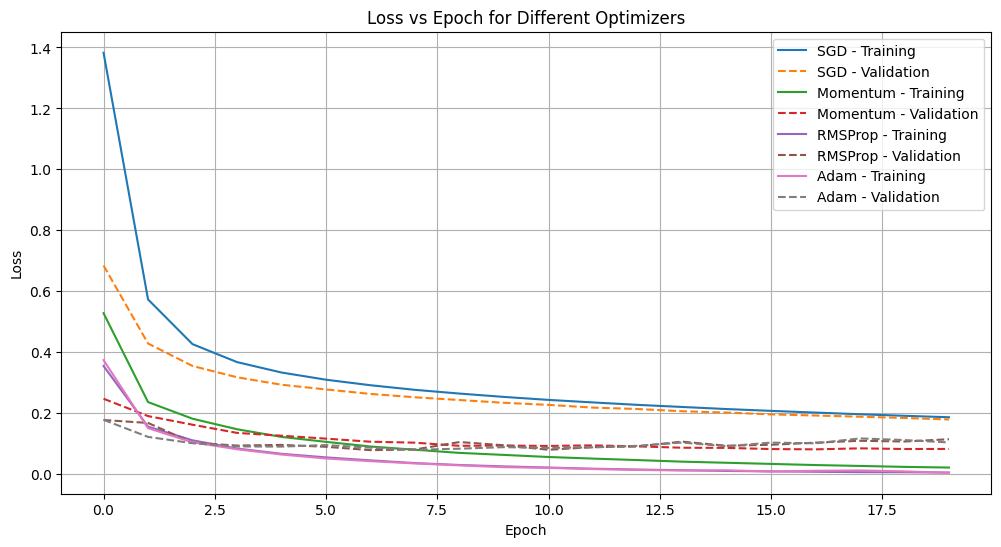

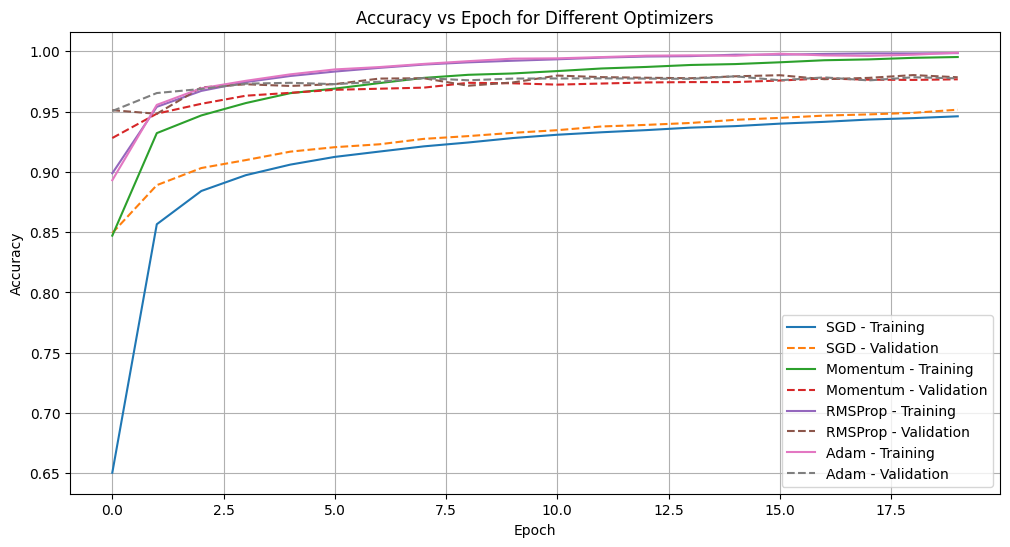

In [ ]:
print("24BAD010-Anusri T")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

validation_size = 10000

x_val = x_train[-validation_size:]
y_val = y_train[-validation_size:]

x_train_new = x_train[:-validation_size]
y_train_new = y_train[:-validation_size]

def create_model():

    model = tf.keras.Sequential([

        tf.keras.layers.Input(shape=(784,)),

        tf.keras.layers.Dense(
            128,
            activation="relu"
        ),

        tf.keras.layers.Dense(
            64,
            activation="relu"
        ),

        tf.keras.layers.Dense(
            10,
            activation="softmax"
        )
    ])

    return model

optimizers = {

    "SGD": tf.keras.optimizers.SGD(
        learning_rate=0.01
    ),

    "Momentum": tf.keras.optimizers.SGD(
        learning_rate=0.01,
        momentum=0.9
    ),

    "RMSProp": tf.keras.optimizers.RMSprop(
        learning_rate=0.001
    ),

    "Adam": tf.keras.optimizers.Adam(
        learning_rate=0.001
    )
}

histories = {}
models = {}

EPOCHS = 20
BATCH_SIZE = 128

for optimizer_name, optimizer in optimizers.items():

    print("\n" + "=" * 60)
    print("Optimizer:", optimizer_name)
    print("=" * 60)

    model = create_model()

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        x_train_new,
        y_train_new,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1
    )

    histories[optimizer_name] = history
    models[optimizer_name] = model

results = []

for optimizer_name in optimizers:

    model = models[optimizer_name]
    history = histories[optimizer_name]

    train_loss, train_accuracy = model.evaluate(
        x_train_new,
        y_train_new,
        verbose=0
    )

    val_loss, val_accuracy = model.evaluate(
        x_val,
        y_val,
        verbose=0
    )

    best_epoch = np.argmax(
        history.history["val_accuracy"]
    ) + 1

    results.append({

        "Optimizer": optimizer_name,

        "Training Accuracy":
            train_accuracy,

        "Validation Accuracy":
            val_accuracy,

        "Training Loss":
            train_loss,

        "Validation Loss":
            val_loss,

        "Best Epoch":
            best_epoch
    })

results_df = pd.DataFrame(results)

print("\nOPTIMIZER COMPARISON")
print("=" * 80)

display(results_df.round(4))

plt.figure(figsize=(12, 6))

for optimizer_name in optimizers:

    history = histories[optimizer_name]

    plt.plot(
        history.history["loss"],
        label=optimizer_name + " - Training"
    )

    plt.plot(
        history.history["val_loss"],
        linestyle="--",
        label=optimizer_name + " - Validation"
    )

plt.title("Loss vs Epoch for Different Optimizers")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()


plt.figure(figsize=(12, 6))

for optimizer_name in optimizers:

    history = histories[optimizer_name]

    plt.plot(
        history.history["accuracy"],
        label=optimizer_name + " - Training"
    )

    plt.plot(
        history.history["val_accuracy"],
        linestyle="--",
        label=optimizer_name + " - Validation"
    )

plt.title("Accuracy vs Epoch for Different Optimizers")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()
plt.show()

In [8]:
import os
import shutil
import subprocess
from google.colab import drive

ROLL_NO = "24BAD010"
STUDENT_NAME = "Anusri T"
GITHUB_USERNAME = "Anusri T"
GITHUB_EMAIL = "anusrit522@gmail.com"

print("=" * 60)
print("TASK D - DEEP LEARNING EXPERIMENT MANAGEMENT")
print("=" * 60)

print("Student Name:", STUDENT_NAME)
print("Roll Number:", ROLL_NO)

drive.mount("/content/drive")

print("\nGoogle Drive mounted successfully.")

BASE_PATH = "/content/drive/MyDrive/DL_Experiment_" + ROLL_NO

NOTEBOOK_PATH = os.path.join(BASE_PATH, "notebooks")
MODEL_PATH = os.path.join(BASE_PATH, "models")
RESULT_PATH = os.path.join(BASE_PATH, "results")
GITHUB_PATH = os.path.join(BASE_PATH, "github_repository")

os.makedirs(NOTEBOOK_PATH, exist_ok=True)
os.makedirs(MODEL_PATH, exist_ok=True)
os.makedirs(RESULT_PATH, exist_ok=True)
os.makedirs(GITHUB_PATH, exist_ok=True)

print("\nExperiment folders created successfully.")
print(BASE_PATH)

print("\nFolder structure:")
print("DL_Experiment_" + ROLL_NO)
print("    notebooks")
print("    models")
print("    results")
print("    github_repository")

if "activation_results_df" in globals():

    activation_file = os.path.join(
        RESULT_PATH,
        "activation_results.csv"
    )

    activation_results_df.to_csv(
        activation_file,
        index=False
    )

    print("\nTask B results saved.")

elif "results_df" in globals():

    activation_file = os.path.join(
        RESULT_PATH,
        "activation_results.csv"
    )

    results_df.to_csv(
        activation_file,
        index=False
    )

    print("\nTask B results saved.")

else:

    print("\nTask B results dataframe not found.")

if "optimizer_results_df" in globals():

    optimizer_file = os.path.join(
        RESULT_PATH,
        "optimizer_results.csv"
    )

    optimizer_results_df.to_csv(
        optimizer_file,
        index=False
    )

    print("Task C results saved.")

else:

    print("Task C results dataframe not found.")

if "models" in globals():

    for name, model in models.items():

        try:

            model_file = os.path.join(
                MODEL_PATH,
                "model_" + name.lower() + ".keras"
            )

            model.save(model_file)

            print(
                name,
                "model saved successfully."
            )

        except Exception as e:

            print(
                "Error saving",
                name,
                ":",
                e
            )

else:

    print("Models from previous tasks were not found.")

README_FILE = os.path.join(
    GITHUB_PATH,
    "README.md"
)

readme_lines = [
    "# ANN Activation Functions and Optimization Algorithms",
    "",
    "## Student Details",
    "",
    "Name: " + STUDENT_NAME,
    "",
    "Roll Number: " + ROLL_NO,
    "",
    "## Aim",
    "",
    "To analyze the impact of different activation functions and optimization algorithms on the performance of Artificial Neural Networks.",
    "",
    "## Software Requirements",
    "",
    "- Python",
    "- TensorFlow",
    "- Google Colab",
    "- Google Drive",
    "- GitHub",
    "- Matplotlib",
    "- NumPy",
    "- Pandas",
    "",
    "## Dataset",
    "",
    "MNIST handwritten digit dataset.",
    "",
    "## Task A",
    "",
    "Sigmoid, Tanh and ReLU activation functions were visualized and compared.",
    "",
    "## Task B",
    "",
    "Sigmoid, Tanh and ReLU were compared using the same ANN architecture.",
    "",
    "## Task C",
    "",
    "SGD, Momentum, RMSProp and Adam were compared using training and validation loss and accuracy.",
    "",
    "## Task D",
    "",
    "Google Drive was used to store models and experiment results. GitHub was used for version control and documentation.",
    "",
    "## Conclusion",
    "",
    "The experiment demonstrated the effect of activation functions and optimization algorithms on ANN performance.",
    ""
]

with open(
    README_FILE,
    "w",
    encoding="utf-8"
) as file:

    file.write("\n".join(readme_lines))

print("\nREADME.md created successfully.")

GITHUB_RESULTS = os.path.join(
    GITHUB_PATH,
    "results"
)

GITHUB_MODELS = os.path.join(
    GITHUB_PATH,
    "models"
)

os.makedirs(
    GITHUB_RESULTS,
    exist_ok=True
)

os.makedirs(
    GITHUB_MODELS,
    exist_ok=True
)

if os.path.exists(RESULT_PATH):

    for filename in os.listdir(RESULT_PATH):

        source = os.path.join(
            RESULT_PATH,
            filename
        )

        destination = os.path.join(
            GITHUB_RESULTS,
            filename
        )

        if os.path.isfile(source):

            shutil.copy2(
                source,
                destination
            )

MODEL_README_FILE = os.path.join(
    GITHUB_MODELS,
    "README.md"
)

model_text = (
    "# Trained Models\n\n"
    "Student Name: " + STUDENT_NAME + "\n\n"
    "Roll Number: " + ROLL_NO + "\n\n"
    "The trained models are stored in Google Drive.\n"
)

with open(
    MODEL_README_FILE,
    "w",
    encoding="utf-8"
) as file:

    file.write(model_text)

INFO_FILE = os.path.join(
    GITHUB_PATH,
    "experiment_info.txt"
)

info_text = (
    "Student Name: " + STUDENT_NAME + "\n"
    "Roll Number: " + ROLL_NO + "\n"
    "Experiment: ANN Activation Functions and Optimizers\n"
    "Dataset: MNIST\n"
    "Framework: TensorFlow\n"
    "Platform: Google Colab\n"
)

with open(
    INFO_FILE,
    "w",
    encoding="utf-8"
) as file:

    file.write(info_text)

os.chdir(GITHUB_PATH)

git_version = subprocess.run(
    ["git", "--version"],
    capture_output=True,
    text=True
)

print("\nGit version:")
print(git_version.stdout.strip())

subprocess.run(
    ["git", "init"],
    capture_output=True,
    text=True
)

subprocess.run(
    [
        "git",
        "config",
        "user.name",
        GITHUB_USERNAME
    ],
    capture_output=True,
    text=True
)

subprocess.run(
    [
        "git",
        "config",
        "user.email",
        GITHUB_EMAIL
    ],
    capture_output=True,
    text=True
)

subprocess.run(
    ["git", "add", "."],
    capture_output=True,
    text=True
)

commit_result = subprocess.run(
    [
        "git",
        "commit",
        "-m",
        "Initial ANN experiment"
    ],
    capture_output=True,
    text=True
)

print("\nGit commit:")
print(commit_result.stdout)

if commit_result.stderr:
    print(commit_result.stderr)

status_result = subprocess.run(
    ["git", "status"],
    capture_output=True,
    text=True
)

print("\nGit status:")
print(status_result.stdout)

log_result = subprocess.run(
    [
        "git",
        "log",
        "--oneline"
    ],
    capture_output=True,
    text=True
)

print("\nGit version history:")
print(log_result.stdout)

print("\n" + "=" * 60)
print("FINAL EXPERIMENT STRUCTURE")
print("=" * 60)

for root, directories, files in os.walk(BASE_PATH):

    level = root.replace(
        BASE_PATH,
        ""
    ).count(os.sep)

    indent = "    " * level

    print(
        indent +
        os.path.basename(root) +
        "/"
    )

    for filename in files:

        print(
            indent +
            "    " +
            filename
        )

print("\n" + "=" * 60)
print("TASK D COMPLETED SUCCESSFULLY")
print("=" * 60)

print("\nGoogle Drive:")
print(BASE_PATH)

print("\nGit Repository:")
print(GITHUB_PATH)

print("\nCompleted:")
print("1. Google Drive mounted")
print("2. Experiment folders created")
print("3. Results saved")
print("4. Models saved")
print("5. README.md created")
print("6. Git repository initialized")
print("7. Files added to Git")
print("8. Initial commit created")
print("9. Git status displayed")
print("10. Version history displayed")

TASK D - DEEP LEARNING EXPERIMENT MANAGEMENT
Student Name: Anusri T
Roll Number: 24BAD010


MessageError: Error: credential propagation was unsuccessful